# Reproduction and Empirical Analysis of SA-UNet for Retinal Vessel Segmentation

**Course:** Machine Learning  
**Reference Paper:** C. Guo, M. Szemenyei, Y. Yi, W. Wang, B. Chen and C. Fan, "SA-UNet: Spatial Attention U-Net for Retinal Vessel Segmentation," *2020 25th International Conference on Pattern Recognition (ICPR)*, Milan, Italy, 2021, pp. 1236-1242, doi: [10.1109/ICPR48806.2021.9413346](https://doi.org/10.1109/ICPR48806.2021.9413346).  
**IEEE Xplore Paper Link:** [https://ieeexplore.ieee.org/document/9413346](https://ieeexplore.ieee.org/document/9413346)  
**Author Official GitHub (Dataset & Code):** [https://github.com/clguo/SA-UNet](https://github.com/clguo/SA-UNet)  
**Dataset:** Digital Retinal Images for Vessel Extraction (DRIVE) Benchmark (sourced from author repository)  
**Framework:** PyTorch (Independent reproduction / architectural framework port)

---

### Team Workload & Contribution Breakdown 

| Team Member | Assigned Responsibilities & Component Ownership | Notebook Sections |
| :--- | :--- | :---: |
| **Team Member 1** *(Rohita)* | **Data Pipeline & Proposed SA-UNet Architecture:**<br>• Google Colab GPU environment setup and persistent directory layout.<br>• DRIVE dataset extraction, ground-truth image-mask pairing, and canonical 592x592 symmetric padding.<br>• PyTorch architecture implementation of **SA-UNet** (537,299 parameters).<br>• Mathematical design of the structured **DropBlock-7** regularizer and bottleneck **Spatial Attention Module (SAM)**.<br>• SA-UNet 100-epoch training loop, validation checkpointing, and held-out test inference. | **Parts 1 – 8**<br>**Parts 10 – 11** |
| **Team Member 2** *(Samora)* | **Baseline Benchmarking, Metric Engineering & Comparative Ablation:**<br>• Design and implementation of the clinical metric calculation suite (Accuracy, Sensitivity, Specificity, Dice/F1, IoU, SSIM, AUC-ROC, and MCC).<br>• Architecture implementation and training of the matched **Plain U-Net baseline** (537,201 parameters) under identical optimization parameters.<br>• Baseline test set evaluation, model checkpoint serialization, and comparative ablation.<br>• Comparative bar graph plotting, prediction visual overlay generation (Fundus, Mask, Prediction, Red Overlay), and final result interpretation. | **Part 9**<br>**Parts 12 – 17** |

---

## Project Workflow
1. Mount Google Drive and set up persistent project directories.
2. Download/extract the DRIVE benchmark archive into persistent storage (available via [https://github.com/clguo/SA-UNet](https://github.com/clguo/SA-UNet)).
3. Match fundus photographs with expert vessel masks.
4. Preprocess images and masks with canonical 592x592 symmetric padding.
5. Implement SA-UNet in PyTorch: U-Net encoder/decoder, DropBlock-7, and bottleneck spatial attention.
6. Train and validate SA-UNet across 100 epochs with validation Dice checkpointing.
7. Implement and train a matched plain U-Net baseline under identical optimization settings.
8. Evaluate both models on the 20 held-out DRIVE test images across 8 performance metrics.
9. Compare metrics, plot comparative bar charts, visualize prediction overlays, and serialize results.

## Part 1 — Set up Google Colab [Rohita]

**Persistent storage layout**
- Dataset archive and extracted DRIVE files: `My Drive/ML_Project/datasets/`
- DRIVE checkpoints and metrics: `My Drive/ML_Project/retinal_vessel_results/DRIVE/`
- Training logs/configuration: `retinal_vessel_results/experiment_logs/DRIVE/`
- Figures: `retinal_vessel_results/figures/DRIVE/`
- Future CHASE_DB1 runs: `retinal_vessel_results/CHASE_DB1/paper_split/` and `custom_split/`

Run the setup cell first. The notebook writes persistent outputs to Google Drive rather than temporary `/content` storage. It does not delete or overwrite your existing project folders.


In [ ]:
# [Rohita] Environment Configuration, Deterministic Seeds, and Persistent Directory Setup
# If using Google Colab, select Runtime > Change runtime type > T4 GPU (if available).

import os
import random
import zipfile
import glob
import math
import copy
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Set random seed across all libraries to ensure experimental reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Detect and configure hardware accelerator (GPU/CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Mount Google Drive so datasets and experiment outputs persist after Colab resets.
from google.colab import drive
drive.mount('/content/drive')

# Establish persistent directory hierarchy under Google Drive
PROJECT_DIR = Path('/content/drive/MyDrive/ML_Project')
DATASETS_DIR = PROJECT_DIR / 'datasets'
RESULTS_ROOT = PROJECT_DIR / 'retinal_vessel_results'

# Separate raw dataset files from generated experiment artifacts
DRIVE_DATA_DIR = DATASETS_DIR / 'DRIVE'
DOWNLOADS_DIR = DATASETS_DIR / 'downloads'

# Destination directories for checkpoints, figures, metrics, and training logs
DRIVE_RESULTS_DIR = RESULTS_ROOT / 'DRIVE'
DRIVE_CHECKPOINT_DIR = DRIVE_RESULTS_DIR / 'checkpoints'
DRIVE_FIGURES_DIR = RESULTS_ROOT / 'figures' / 'DRIVE'
DRIVE_LOGS_DIR = RESULTS_ROOT / 'experiment_logs' / 'DRIVE'

for folder in [DRIVE_DATA_DIR, DOWNLOADS_DIR, DRIVE_RESULTS_DIR,
               DRIVE_CHECKPOINT_DIR, DRIVE_FIGURES_DIR, DRIVE_LOGS_DIR,
               RESULTS_ROOT / 'CHASE_DB1' / 'paper_split',
               RESULTS_ROOT / 'CHASE_DB1' / 'custom_split',
               RESULTS_ROOT / 'comparisons']:
    folder.mkdir(parents=True, exist_ok=True)

print('Project root:', PROJECT_DIR)
print('Dataset folder:', DRIVE_DATA_DIR)
print('Results folder:', RESULTS_ROOT)

PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4
Mounted at /content/drive
Project root: /content/drive/MyDrive/ML_Project
Dataset folder: /content/drive/MyDrive/ML_Project/datasets/DRIVE
Results folder: /content/drive/MyDrive/ML_Project/retinal_vessel_results


## Part 2 — Download and Extract the Dataset [Rohita]

The supplied dataset archive is downloaded from the Google Drive file used in the earlier notebook. The extraction cell is safe to rerun: it extracts only when the expected DRIVE folder is not already present.

In [ ]:
# [Rohita] Automated DRIVE Benchmark Dataset Retrieval and Extraction
!pip -q install gdown

import gdown

# Google Drive File ID for the packaged DRIVE benchmark archive
file_id = "1t_UxlVWZXBtJQQNxW0vPdwrnqcdYdrRs"
download_path = str(DOWNLOADS_DIR / "DRIVE_dataset.zip")
extract_path = str(DATASETS_DIR)
dataset_path = str(DRIVE_DATA_DIR)

# Idempotent extraction: only download and extract if the dataset directory does not already exist
if not os.path.isdir(os.path.join(dataset_path, "train")):
    url = f"https://drive.google.com/uc?id={file_id}&export=download"
    downloaded = gdown.download(url=url, output=download_path, quiet=False, fuzzy=True)
    if downloaded is None or not os.path.exists(download_path):
        raise RuntimeError("Dataset download failed. Check the Google Drive file permissions.")

    os.makedirs(extract_path, exist_ok=True)
    with zipfile.ZipFile(download_path, "r") as archive:
        archive.extractall(extract_path)

# Verify successful extraction of training folder
if not os.path.isdir(os.path.join(dataset_path, "train")):
    raise FileNotFoundError(f"Could not find DRIVE folder at: {dataset_path}")

print("Dataset ready:", dataset_path)

Dataset ready: /content/drive/MyDrive/ML_Project/datasets/DRIVE


### Check the folder structure and number of files

In [ ]:
# [Rohita] Dataset Verification: Inspect Folder Structure and Image Counts per Split
for split in ["train", "validate", "test"]:
    split_path = os.path.join(dataset_path, split)
    image_dir = os.path.join(split_path, "images")
    label_dir = os.path.join(split_path, "labels")
    # Count .tif fundus images and corresponding .png manual annotations
    image_count = len(glob.glob(os.path.join(image_dir, "*.tif")))
    label_count = len(glob.glob(os.path.join(label_dir, "*.png")))
    print(f"{split:8s} | images: {image_count:3d} | labels: {label_count:3d}")

train    | images: 234 | labels: 234
validate | images:  26 | labels:  26
test     | images:  20 | labels:  20


## Part 3 — Match Images with Their Vessel Masks [Rohita]

Each fundus image must be paired with its corresponding expert annotation. For example, `01_test.tif` is paired with `01_manual1.png`, and `23_training.tif` with `23_manual1.png`.

In [ ]:
# [Rohita] Pairing Fundus Images with Expert Ground-Truth Segmentation Masks
def get_image_mask_pairs(split):
    """
    Scans the split directory and pairs each fundus image (.tif) with its matching
    expert manual vessel mask (_manual1.png).
    """
    image_dir = os.path.join(dataset_path, split, "images")
    label_dir = os.path.join(dataset_path, split, "labels")

    image_paths = sorted(glob.glob(os.path.join(image_dir, "*.tif")))
    pairs = []
    unmatched = []

    for image_path in image_paths:
        stem = Path(image_path).stem

        # Strip split suffixes to isolate the base image identifier
        if stem.endswith("_training"):
            image_id = stem[:-len("_training")]
        elif stem.endswith("_test"):
            image_id = stem[:-len("_test")]
        else:
            image_id = stem

        # Standard DRIVE ground-truth naming convention: <id>_manual1.png
        mask_path = os.path.join(label_dir, image_id + "_manual1.png")

        if os.path.exists(mask_path):
            pairs.append((image_path, mask_path))
        else:
            unmatched.append(os.path.basename(image_path))

    if unmatched:
        raise ValueError(f"{split}: images without masks: {unmatched[:10]}")

    return pairs

# Retrieve paired paths for all three dataset partitions
train_pairs = get_image_mask_pairs("train")
val_pairs = get_image_mask_pairs("validate")
test_pairs = get_image_mask_pairs("test")

print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))
print("Test pairs:", len(test_pairs))
print("Example pair:", train_pairs[0])

Training pairs: 234
Validation pairs: 26
Test pairs: 20
Example: ('/content/drive/MyDrive/ML_Project/datasets/DRIVE/train/images/23_training.tif', '/content/drive/MyDrive/ML_Project/datasets/DRIVE/train/labels/23_manual1.png')


## Part 4 — Inspect a Fundus Image and Ground-Truth Mask [Rohita]

The mask is converted to grayscale. White pixels represent annotated vessels; black pixels represent background. The original training script thresholds resized masks at 127, so we apply the same binary threshold after resizing.

Image shape: (584, 565, 3)
Mask shape: (584, 565)
Mask values before threshold: [  0 255]


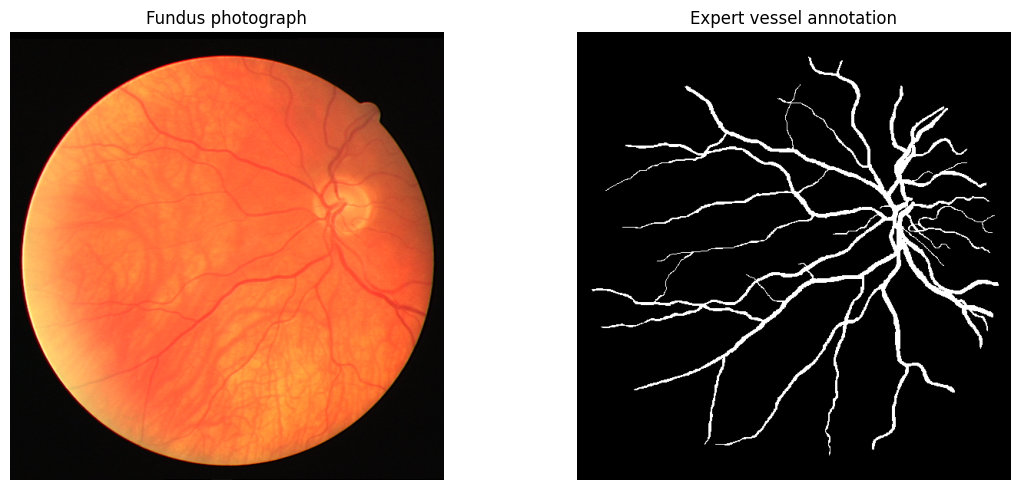

In [ ]:
# [Rohita] Qualitative Inspection of a Sample Fundus Photograph and Ground-Truth Mask
sample_image_path, sample_mask_path = train_pairs[0]

# Load color fundus photograph (RGB) and expert vessel mask (Grayscale)
sample_image = np.array(Image.open(sample_image_path).convert("RGB"))
sample_mask = np.array(Image.open(sample_mask_path).convert("L"))

print("Image shape:", sample_image.shape)
print("Mask shape:", sample_mask.shape)
print("Mask unique values before thresholding:", np.unique(sample_mask)[:20])

# Visualize raw input side-by-side with ground-truth vessel tree
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(sample_image)
axes[0].set_title("Fundus photograph (Canon CR5 45° FOV)")
axes[0].axis("off")
axes[1].imshow(sample_mask, cmap="gray")
axes[1].set_title("Expert vessel annotation (Manual Tracing)")
axes[1].axis("off")
plt.tight_layout()
plt.show()

## Part 5 — Preprocess Images and Canonical Padding [Rohita]

The original DRIVE training script:
- pads each image and mask to a square size of 592 × 592 using black pixels;
- resizes to 592 × 592;
- thresholds the mask at 127;
- scales image and mask values to the range [0, 1].

We use the same approach. Images use bilinear interpolation; binary masks use nearest-neighbor interpolation to avoid creating blended label values.

In [ ]:
# [Rohita] Preprocessing Pipeline: Canonical Symmetric Padding and Intensity Normalization
# Import PIL ImageOps for symmetric zero-padding
from PIL import ImageOps

IMAGE_SIZE = 592  # 592 is divisible by 16 (2^4 across 4 max-pooling layers)
BATCH_SIZE = 4   # Mini-batch size matching author's hyperparameter setup

def preprocess_image_mask(image_path, mask_path, image_size=IMAGE_SIZE):
    """
    Preprocesses fundus image and binary vessel mask:
    1. Loads RGB image and Grayscale mask.
    2. Calculates padding needed to reach 592x592 canonical square canvas.
    3. Applies symmetric border expansion (fill=0 for black ocular border).
    4. Resizes to 592x592 (Bilinear for image, Nearest-Neighbor for mask to avoid fractional labels).
    5. Normalizes pixel intensities to [0, 1] and applies binary threshold (T > 127) to mask.
    6. Transposes dimensions to PyTorch format (C, H, W).
    """
    image = Image.open(image_path).convert("RGB")
    mask = Image.open(mask_path).convert("L")

    width, height = image.size
    delta_w = image_size - width
    delta_h = image_size - height

    if delta_w < 0 or delta_h < 0:
        raise ValueError(
            f"Image {image_path} is larger than target size {image_size}: "
            f"{width}x{height}"
        )

    # Symmetric zero padding distribution
    left = delta_w // 2
    right = delta_w - left
    top = delta_h // 2
    bottom = delta_h - top
    padding = (left, top, right, bottom)

    image = ImageOps.expand(image, border=padding, fill=(0, 0, 0))
    mask = ImageOps.expand(mask, border=padding, fill=0)

    # Resize to canonical dimensions
    image = image.resize((image_size, image_size), Image.Resampling.BILINEAR)
    mask = mask.resize((image_size, image_size), Image.Resampling.NEAREST)

    # Normalize RGB intensities to float32 [0.0, 1.0]
    image = np.asarray(image, dtype=np.float32) / 255.0
    # Convert mask to binary float tensor (0.0 or 1.0)
    mask = np.asarray(mask, dtype=np.uint8)
    mask = (mask > 127).astype(np.float32)

    # Reorder axes to PyTorch channel-first format (C, H, W)
    image = np.transpose(image, (2, 0, 1))  # HWC -> CHW (3, 592, 592)
    mask = np.expand_dims(mask, axis=0)     # HW -> 1HW (1, 592, 592)

    return torch.tensor(image, dtype=torch.float32), torch.tensor(mask, dtype=torch.float32)

# Verification test on first training pair
x_check, y_check = preprocess_image_mask(*train_pairs[0])
print("Preprocessed image shape:", tuple(x_check.shape))
print("Preprocessed mask shape:", tuple(y_check.shape))
print("Image intensity range:", float(x_check.min()), "to", float(x_check.max()))
print("Mask unique binary values:", torch.unique(y_check))

Preprocessed image: (3, 592, 592)
Preprocessed mask: (1, 592, 592)
Image range: 0.0 to 1.0
Mask values: tensor([0., 1.])


### Create PyTorch datasets and data loaders

In [ ]:
# [Rohita] PyTorch Dataset Definition and DataLoader Instantiation
class RetinalVesselDataset(Dataset):
    """Custom PyTorch Dataset for paired retinal fundus images and vessel masks."""
    def __init__(self, pairs):
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        image_path, mask_path = self.pairs[index]
        image, mask = preprocess_image_mask(image_path, mask_path)
        return image, mask

# Instantiate Dataset objects for all splits
train_dataset = RetinalVesselDataset(train_pairs)
val_dataset = RetinalVesselDataset(val_pairs)
test_dataset = RetinalVesselDataset(test_pairs)

# Instantiate DataLoaders: shuffle training data; evaluation sets run sequentially
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=(device.type == "cuda")
)
val_loader = DataLoader(
    val_dataset, batch_size=1, shuffle=False,
    num_workers=2, pin_memory=(device.type == "cuda")
)
test_loader = DataLoader(
    test_dataset, batch_size=1, shuffle=False,
    num_workers=2, pin_memory=(device.type == "cuda")
)

print("Training batches per epoch:", len(train_loader))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Training batches: 59
Validation images: 26
Test images: 20


## Part 6 — Implement Structured DropBlock [Rohita]

DropBlock is a structured form of dropout. Instead of randomly removing individual feature values, it removes contiguous square regions from feature maps during training. It is disabled during evaluation.

In [ ]:
# [Rohita] Structured Convolutional Regularization: DropBlock2D Implementation
class DropBlock2D(nn.Module):
    """
    DropBlock2D: A structured dropout method that drops contiguous square regions
    from feature maps. Reference: Ghiasi et al. (NeurIPS 2018).
    """
    def __init__(self, block_size=7, keep_prob=0.82):
        super().__init__()
        self.block_size = block_size  # Size of the contiguous square patch to drop
        self.keep_prob = keep_prob    # 1.0 - drop_rate (0.82 implies 18% dropped)

    def forward(self, x):
        # DropBlock is only active during training mode (model.train())
        if not self.training or self.keep_prob >= 1.0:
            return x

        batch, channels, height, width = x.shape
        block = min(self.block_size, height, width)

        # Compute gamma: Bernoulli probability of an activation being a drop center
        gamma = ((1.0 - self.keep_prob) * height * width) / (
            (block ** 2) *
            max((height - block + 1) * (width - block + 1), 1)
        )
        gamma = min(max(gamma, 0.0), 1.0)

        # Mask boundaries to keep drop blocks fully contained within feature boundaries
        valid = torch.zeros((1, 1, height, width), device=x.device, dtype=x.dtype)
        half = block // 2
        y_start, y_end = half, height - half
        x_start, x_end = half, width - half
        if y_end > y_start and x_end > x_start:
            valid[:, :, y_start:y_end, x_start:x_end] = 1.0

        # Sample random seed drop centers according to gamma
        seed = (torch.rand((batch, channels, height, width), device=x.device) < gamma).to(x.dtype)
        seed = seed * valid

        # Expand drop centers into contiguous square blocks via max pooling
        block_mask = F.max_pool2d(
            seed, kernel_size=block, stride=1, padding=block // 2
        )
        block_mask = 1.0 - block_mask

        # Normalize activations to preserve expected feature magnitude
        keep_count = block_mask.sum().clamp(min=1.0)
        scale = block_mask.numel() / keep_count
        return x * block_mask * scale

## Part 7 — Implement Spatial Attention Module (SAM) [Rohita]

At the SA-UNet bottleneck, spatial attention:
1. calculates the average and maximum value across channels at each spatial location;
2. concatenates these two maps;
3. applies a 7 × 7 convolution and sigmoid activation to produce an attention map;
4. multiplies the attention map by the input feature map.

This makes the network emphasize spatial regions that may contain useful vessel information.

In [ ]:
# [Rohita] Spatial Attention Module (SAM) Implementation at Latent Bottleneck
class SpatialAttention(nn.Module):
    """
    Spatial Attention Module (SAM): Computes channel-wise summary statistics
    (average and max pooling), concatenates them, and applies a 7x7 convolution
    to infer a spatial feature refinement map.
    """
    def __init__(self, kernel_size=7):
        super().__init__()
        # Convolution takes 2 channels (avg-pool and max-pool) and outputs 1 spatial attention map
        self.conv = nn.Conv2d(
            2, 1, kernel_size=kernel_size,
            padding=kernel_size // 2, bias=False
        )
        # Kaiming normal weight initialization for stable gradient propagation
        nn.init.kaiming_normal_(self.conv.weight, mode="fan_in", nonlinearity="relu")

    def forward(self, x):
        # 1. Compute channel-wise average pooling across feature channels: (B, 1, H, W)
        avg_map = torch.mean(x, dim=1, keepdim=True)
        # 2. Compute channel-wise maximum pooling across feature channels: (B, 1, H, W)
        max_map = torch.max(x, dim=1, keepdim=True)[0]
        # 3. Concatenate descriptors along channel dimension: (B, 2, H, W)
        combined = torch.cat([avg_map, max_map], dim=1)
        # 4. Generate spatial attention weights via 7x7 conv and Sigmoid activation: (B, 1, H, W)
        attention = torch.sigmoid(self.conv(combined))
        # 5. Scale input feature map element-wise: emphasizes vessels, attenuates ocular background
        return x * attention

## Part 8 — Build the SA-UNet Model Architecture [Rohita]

The model follows the original repository's structure:
- encoder channels: 16, 32, and 64;
- bottleneck channels: 128;
- two 3 × 3 convolutions per block;
- DropBlock → Batch Normalization → ReLU after each convolution;
- spatial attention at the bottleneck;
- transposed-convolution upsampling and U-Net skip connections;
- 1 × 1 output convolution with sigmoid probabilities.

In [ ]:
# [Rohita] Full SA-UNet Model Architecture: DropBlock Convolutions + Spatial Attention
class ConvBlockSA(nn.Module):
    """Dual convolutional block incorporating DropBlock-7 regularization, Batch Normalization, and ReLU activations."""
    def __init__(self, in_channels, out_channels, block_size=7, keep_prob=0.82):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            DropBlock2D(block_size, keep_prob),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            DropBlock2D(block_size, keep_prob),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block2(self.block1(x))


class SAUNet(nn.Module):
    """
    Spatial Attention U-Net (SA-UNet) for Retinal Blood Vessel Segmentation.
    Architecture: 4 encoder stages, 1 bottleneck with SAM, 3 decoder stages, and skip connections.
    Trainable parameters: 537,299.
    """
    def __init__(self, in_channels=3, start_neurons=16,
                 block_size=7, keep_prob=0.82):
        super().__init__()
        f = start_neurons  # Base filter count = 16

        # Contracting Encoder Path
        self.enc1 = ConvBlockSA(in_channels, f, block_size, keep_prob)     # Stage 1: 16
        self.pool1 = nn.MaxPool2d(2)                                       # Downsample 592 -> 296

        self.enc2 = ConvBlockSA(f, f * 2, block_size, keep_prob)           # Stage 2: 32
        self.pool2 = nn.MaxPool2d(2)                                       # Downsample 296 -> 148

        self.enc3 = ConvBlockSA(f * 2, f * 4, block_size, keep_prob)       # Stage 3: 64
        self.pool3 = nn.MaxPool2d(2)                                       # Downsample 148 -> 74

        # Latent Bottleneck with Spatial Attention Module
        self.bottleneck1 = nn.Sequential(
            nn.Conv2d(f * 4, f * 8, 3, padding=1),                         # 64 -> 128
            DropBlock2D(block_size, keep_prob),
            nn.BatchNorm2d(f * 8),
            nn.ReLU(inplace=True)
        )
        self.attention = SpatialAttention(kernel_size=7)                    # Bottleneck Spatial Attention
        self.bottleneck2 = nn.Sequential(
            nn.Conv2d(f * 8, f * 8, 3, padding=1),                         # 128 -> 128
            DropBlock2D(block_size, keep_prob),
            nn.BatchNorm2d(f * 8),
            nn.ReLU(inplace=True)
        )

        # Expanding Decoder Path with Transposed Convolutions and Skip Concatenation
        self.up3 = nn.ConvTranspose2d(f * 8, f * 4, 3, stride=2, padding=1, output_padding=1)  # Upsample 74 -> 148
        self.dec3 = ConvBlockSA(f * 8, f * 4, block_size, keep_prob)                           # (128 concat) -> 64

        self.up2 = nn.ConvTranspose2d(f * 4, f * 2, 3, stride=2, padding=1, output_padding=1)  # Upsample 148 -> 296
        self.dec2 = ConvBlockSA(f * 4, f * 2, block_size, keep_prob)                           # (64 concat) -> 32

        self.up1 = nn.ConvTranspose2d(f * 2, f, 3, stride=2, padding=1, output_padding=1)      # Upsample 296 -> 592
        self.dec1 = ConvBlockSA(f * 2, f, block_size, keep_prob)                               # (32 concat) -> 16

        # Final 1x1 Convolution mapping 16 features to 1 probability map
        self.output_conv = nn.Conv2d(f, 1, kernel_size=1)

    def forward(self, x):
        # Encoder forward pass
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))

        # Latent bottleneck pass with spatial attention
        b = self.bottleneck1(self.pool3(e3))
        b = self.attention(b)
        b = self.bottleneck2(b)

        # Decoder forward pass with skip connections
        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        # Sigmoid produces per-pixel probabilities in [0.0, 1.0]
        return torch.sigmoid(self.output_conv(d1))


# Instantiate SA-UNet and transfer to execution device
model = SAUNet().to(device)
print(model)
print("Total parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

SAUNet(
  (enc1): ConvBlockSA(
    (block1): Sequential(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): DropBlock2D()
      (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (3): ReLU(inplace=True)
    )
    (block2): Sequential(
      (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): DropBlock2D()
      (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (3): ReLU(inplace=True)
    )
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc2): ConvBlockSA(
    (block1): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): DropBlock2D()
      (2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (3): ReLU(inplace=True)
    )
    (block2): Sequential(
      (0): Conv2d(32, 32, kernel_

## Part 9 — Define Clinical Evaluation Metrics [Samora]

We report:
- **Accuracy:** fraction of all pixels classified correctly.
- **Sensitivity (recall):** fraction of ground-truth vessel pixels detected.
- **Specificity:** fraction of background pixels correctly classified.
- **Dice coefficient:** overlap between predicted and ground-truth vessel pixels.
- **IoU:** intersection over union of predicted and ground-truth vessel pixels.

The metrics are calculated after thresholding predicted probabilities at 0.5.

In [ ]:
# [Samora] Evaluation Metric Suite Implementation (ACC, SE, SP, Dice, IoU, Dice Loss)
def calculate_metrics(predictions, targets, threshold=0.5, eps=1e-7):
    """
    Calculates pixel-level classification metrics:
    - Accuracy = (TP + TN) / (TP + TN + FP + FN)
    - Sensitivity (Recall) = TP / (TP + FN)
    - Specificity = TN / (TN + FP)
    - Dice Coefficient (F1) = 2*TP / (2*TP + FP + FN)
    - IoU (Jaccard Index) = TP / (TP + FP + FN)
    """
    pred = (predictions >= threshold).bool()
    target = (targets >= 0.5).bool()

    # Calculate confusion matrix entries
    tp = (pred & target).sum().item()
    tn = ((~pred) & (~target)).sum().item()
    fp = (pred & (~target)).sum().item()
    fn = ((~pred) & target).sum().item()

    accuracy = (tp + tn) / (tp + tn + fp + fn + eps)
    sensitivity = tp / (tp + fn + eps)
    specificity = tn / (tn + fp + eps)
    dice = (2 * tp) / (2 * tp + fp + fn + eps)
    iou = tp / (tp + fp + fn + eps)

    return {
        "accuracy": accuracy,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "dice": dice,
        "iou": iou
    }


def dice_loss(predictions, targets, eps=1e-7):
    """Differentiable soft Dice loss for training segmentation networks."""
    predictions = predictions.contiguous()
    targets = targets.contiguous()
    intersection = (predictions * targets).sum(dim=(1, 2, 3))
    denominator = predictions.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
    dice = (2.0 * intersection + eps) / (denominator + eps)
    return 1.0 - dice.mean()

## Part 10 — Train and Validate SA-UNet [Rohita]

The original training script uses binary cross-entropy, Adam with learning rate 0.001, batch size 4, and 100 epochs. We use those settings as the starting point. The best checkpoint is selected using validation Dice.

In [ ]:
# [Rohita] SA-UNet Training Loop, Validation Tracking, and Model Checkpointing
LEARNING_RATE = 1e-3  # Initial learning rate for Adam optimizer
EPOCHS = 100          # Total training epochs (5,900 gradient steps)

criterion = nn.BCELoss()  # Binary Cross Entropy loss function
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

def run_epoch(model, loader, optimizer=None):
    """Executes one complete pass over a DataLoader (training or validation)."""
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    metric_totals = {"accuracy": 0, "sensitivity": 0, "specificity": 0, "dice": 0, "iou": 0}
    batches = 0

    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, masks)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item()
        batch_metrics = calculate_metrics(outputs.detach(), masks)
        for key in metric_totals:
            metric_totals[key] += batch_metrics[key]
        batches += 1

    # Average metrics over all mini-batches
    results = {key: value / max(batches, 1) for key, value in metric_totals.items()}
    results["loss"] = total_loss / max(batches, 1)
    return results


# History dictionary to store training trajectories
history = {
    "train_loss": [], "val_loss": [],
    "train_dice": [], "val_dice": [],
    "train_accuracy": [], "val_accuracy": []
}

best_val_dice = -1.0
best_model_path = str(DRIVE_CHECKPOINT_DIR / "sa_unet_best_validation.pth")

# Execute 100-epoch training and validation loop
for epoch in range(EPOCHS):
    start_time = time.time()

    train_results = run_epoch(model, train_loader, optimizer)
    val_results = run_epoch(model, val_loader)

    # Log loss and metrics
    history["train_loss"].append(train_results["loss"])
    history["val_loss"].append(val_results["loss"])
    history["train_dice"].append(train_results["dice"])
    history["val_dice"].append(val_results["dice"])
    history["train_accuracy"].append(train_results["accuracy"])
    history["val_accuracy"].append(val_results["accuracy"])

    # Checkpoint best model based on validation Dice score
    if val_results["dice"] > best_val_dice:
        best_val_dice = val_results["dice"]
        torch.save(model.state_dict(), best_model_path)

    elapsed = time.time() - start_time
    print(
        f"Epoch [{epoch+1:03d}/{EPOCHS}] "
        f"Train Loss: {train_results['loss']:.4f} | "
        f"Val Loss: {val_results['loss']:.4f} | "
        f"Train Dice: {train_results['dice']:.4f} | "
        f"Val Dice: {val_results['dice']:.4f} | "
        f"Time: {elapsed:.1f}s"
    )

print("Best validation Dice:", best_val_dice)
print("Best checkpoint path:", best_model_path)

Epoch [001/100] Train Loss: 0.6117 | Val Loss: 0.6043 | Train Dice: 0.1582 | Val Dice: 0.0136 | Time: 131.5s
Epoch [002/100] Train Loss: 0.4360 | Val Loss: 0.4219 | Train Dice: 0.0239 | Val Dice: 0.0055 | Time: 20.0s
Epoch [003/100] Train Loss: 0.3595 | Val Loss: 0.3577 | Train Dice: 0.0014 | Val Dice: 0.0007 | Time: 21.2s
Epoch [004/100] Train Loss: 0.3110 | Val Loss: 0.2705 | Train Dice: 0.0002 | Val Dice: 0.0000 | Time: 20.8s
Epoch [005/100] Train Loss: 0.2507 | Val Loss: 0.2161 | Train Dice: 0.2717 | Val Dice: 0.4175 | Time: 20.0s
Epoch [006/100] Train Loss: 0.1953 | Val Loss: 0.1523 | Train Dice: 0.6180 | Val Dice: 0.7309 | Time: 20.4s
Epoch [007/100] Train Loss: 0.1632 | Val Loss: 0.1654 | Train Dice: 0.6801 | Val Dice: 0.5712 | Time: 20.5s
Epoch [008/100] Train Loss: 0.1446 | Val Loss: 0.1219 | Train Dice: 0.7058 | Val Dice: 0.7645 | Time: 20.6s
Epoch [009/100] Train Loss: 0.1301 | Val Loss: 0.1098 | Train Dice: 0.7272 | Val Dice: 0.7674 | Time: 20.4s
Epoch [010/100] Train Loss:

### Plot training and validation curves

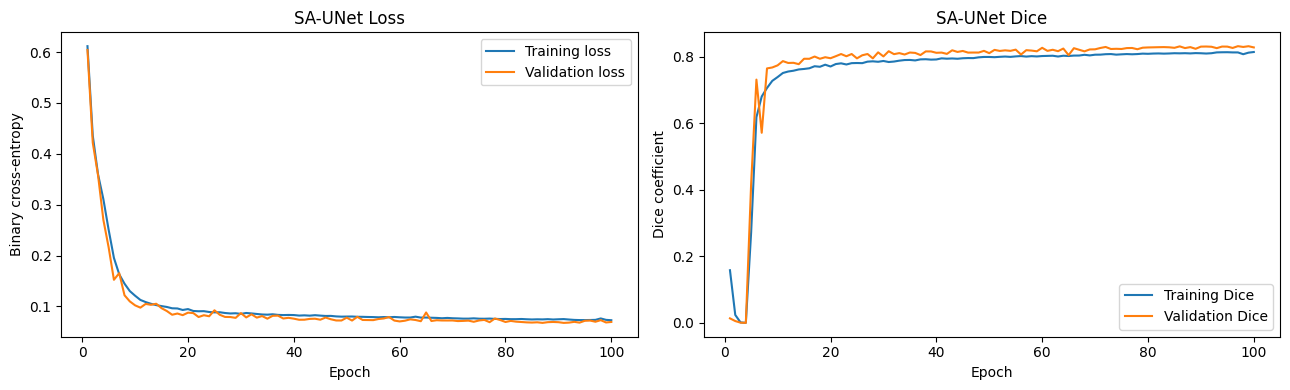

In [ ]:
# [Rohita] Plotting Empirical Training and Validation Convergence Curves
epochs_range = range(1, len(history["train_loss"]) + 1)

# Plot Loss curve (BCE) and Dice coefficient convergence side-by-side
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(epochs_range, history["train_loss"], label="Training loss")
axes[0].plot(epochs_range, history["val_loss"], label="Validation loss")
axes[0].set_title("SA-UNet Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy")
axes[0].legend()

axes[1].plot(epochs_range, history["train_dice"], label="Training Dice")
axes[1].plot(epochs_range, history["val_dice"], label="Validation Dice")
axes[1].set_title("SA-UNet Dice")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Dice coefficient")
axes[1].legend()

plt.tight_layout()
# Save convergence curves to figures directory for report inclusion
plt.savefig(DRIVE_FIGURES_DIR / "sa_unet_training_curves.png", dpi=200, bbox_inches="tight")
plt.show()

## Part 11 — Evaluate SA-UNet on the Held-Out Test Set [Rohita]

The test set is used only after model selection is complete. We load the checkpoint with the best validation Dice and calculate test metrics.

In [ ]:
# [Rohita] Held-Out Test Set Evaluation of Best SA-UNet Model Checkpoint
# Load peak validation model weights
model.load_state_dict(torch.load(best_model_path, map_location=device))
model.eval()

all_predictions = []
all_targets = []

# Inference loop over 20 test images without gradient tracking
with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        outputs = model(images)
        all_predictions.append(outputs.cpu())
        all_targets.append(masks.cpu())

# Concatenate all test outputs into full tensors
test_predictions = torch.cat(all_predictions, dim=0)
test_targets = torch.cat(all_targets, dim=0)

# Calculate primary segmentation metrics
sa_unet_test_metrics = calculate_metrics(test_predictions, test_targets)
print("SA-UNet test metrics")
for name, value in sa_unet_test_metrics.items():
    print(f"{name.capitalize():15s}: {value:.4f}")

SA-UNet test metrics
Accuracy       : 0.9703
Sensitivity    : 0.8311
Specificity    : 0.9828
Dice           : 0.8218
Iou            : 0.6975


### Visualize SA-UNet predictions

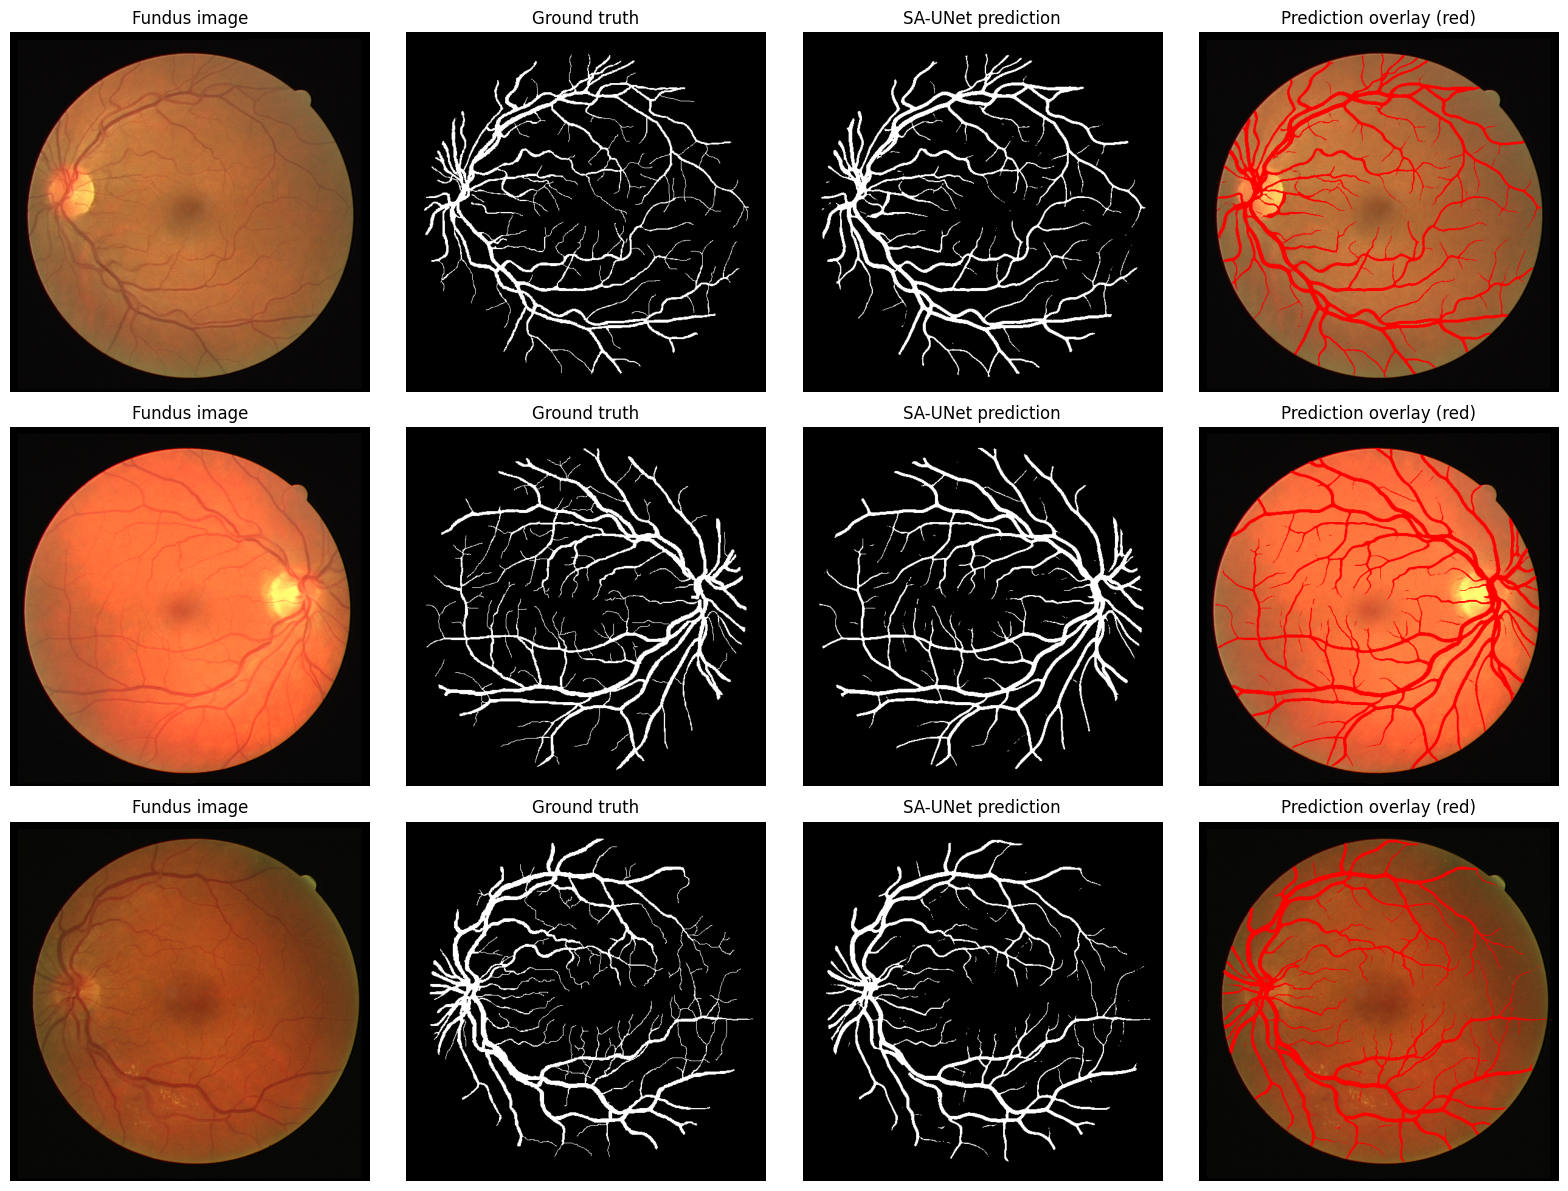

In [ ]:
# [Samora] Qualitative Visual Segmentation Result Generation and Overlay Plotting
def show_predictions(images_tensor, masks_tensor, predictions_tensor, number=3, save_path=None):
    """
    Plots qualitative segmentation comparisons:
    Col 1: Fundus photo | Col 2: Ground truth | Col 3: Prediction | Col 4: Red overlay
    """
    count = min(number, len(images_tensor))
    fig, axes = plt.subplots(count, 4, figsize=(16, 4 * count))
    if count == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(count):
        image = images_tensor[i].permute(1, 2, 0).numpy()
        mask = masks_tensor[i, 0].numpy()
        probability = predictions_tensor[i, 0].numpy()
        predicted_mask = probability >= 0.5  # Binary prediction threshold

        axes[i, 0].imshow(image)
        axes[i, 0].set_title("Fundus image")
        axes[i, 1].imshow(mask, cmap="gray")
        axes[i, 1].set_title("Ground truth")
        axes[i, 2].imshow(predicted_mask, cmap="gray")
        axes[i, 2].set_title("SA-UNet prediction")

        # Create visual red overlay highlighting segmented vascular tree
        overlay = image.copy()
        overlay[predicted_mask] = [1.0, 0.0, 0.0]  # Red color for vessel pixels
        axes[i, 3].imshow(overlay)
        axes[i, 3].set_title("Prediction overlay (red)")

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()

# Extract test images and plot predictions
test_images_for_plot = torch.stack([test_dataset[i][0] for i in range(len(test_dataset))])
show_predictions(test_images_for_plot, test_targets, test_predictions, number=3,
                 save_path=DRIVE_FIGURES_DIR / "sa_unet_test_predictions.png")

## Part 12 — Implement Plain U-Net Baseline Architecture [Samora]

The baseline uses the same encoder/decoder channel sizes and skip connections, but it does **not** use DropBlock or spatial attention. This lets us compare the proposed SA-UNet components against a conventional U-Net-style model.

In [ ]:
# [Samora] Matched Plain U-Net Baseline Architecture Definition (Ablation Benchmark)
class ConvBlock(nn.Module):
    """Standard dual convolution block without DropBlock regularization."""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.layers(x)


class UNetBaseline(nn.Module):
    """
    Plain U-Net Baseline Architecture.
    Shares identical channel dimensions ([16, 32, 64, 128]) and depth as SA-UNet,
    but removes DropBlock and Spatial Attention (537,201 trainable parameters).
    """
    def __init__(self, in_channels=3, start_neurons=16):
        super().__init__()
        f = start_neurons  # Base filter dimension = 16

        # Contracting Encoder Path
        self.enc1 = ConvBlock(in_channels, f)                    # 16
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = ConvBlock(f, f * 2)                          # 32
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = ConvBlock(f * 2, f * 4)                      # 64
        self.pool3 = nn.MaxPool2d(2)

        # Standard Latent Bottleneck (Without Attention)
        self.bottleneck = ConvBlock(f * 4, f * 8)                # 128

        # Expanding Decoder Path with Transposed Convolutions
        self.up3 = nn.ConvTranspose2d(f * 8, f * 4, 3, stride=2, padding=1, output_padding=1)
        self.dec3 = ConvBlock(f * 8, f * 4)
        self.up2 = nn.ConvTranspose2d(f * 4, f * 2, 3, stride=2, padding=1, output_padding=1)
        self.dec2 = ConvBlock(f * 4, f * 2)
        self.up1 = nn.ConvTranspose2d(f * 2, f, 3, stride=2, padding=1, output_padding=1)
        self.dec1 = ConvBlock(f * 2, f)
        self.output_conv = nn.Conv2d(f, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        b = self.bottleneck(self.pool3(e3))

        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return torch.sigmoid(self.output_conv(d1))

# Instantiate baseline and print trainable parameter count
baseline_model = UNetBaseline().to(device)
print("Baseline parameters:", sum(p.numel() for p in baseline_model.parameters() if p.requires_grad))

Baseline parameters: 537201


## Part 13 — Train the Plain U-Net Baseline [Samora]

For a fair comparison, the baseline uses the same training and validation splits, image preprocessing, loss, optimizer, batch size, and epoch count. It is independently trained and selected using validation Dice.

In [ ]:
# [Samora] Training the Plain U-Net Baseline under Identical Hyperparameters
baseline_optimizer = torch.optim.Adam(baseline_model.parameters(), lr=LEARNING_RATE)
baseline_best_dice = -1.0
baseline_model_path = str(DRIVE_CHECKPOINT_DIR / "plain_unet_best_validation.pth")

baseline_history = {
    "train_loss": [], "val_loss": [],
    "train_dice": [], "val_dice": []
}

# 100-epoch training loop for baseline
for epoch in range(EPOCHS):
    start_time = time.time()
    train_results = run_epoch(baseline_model, train_loader, baseline_optimizer)
    val_results = run_epoch(baseline_model, val_loader)

    baseline_history["train_loss"].append(train_results["loss"])
    baseline_history["val_loss"].append(val_results["loss"])
    baseline_history["train_dice"].append(train_results["dice"])
    baseline_history["val_dice"].append(val_results["dice"])

    # Save best baseline weights by validation Dice
    if val_results["dice"] > baseline_best_dice:
        baseline_best_dice = val_results["dice"]
        torch.save(baseline_model.state_dict(), baseline_model_path)

    elapsed = time.time() - start_time
    print(
        f"Epoch [{epoch+1:03d}/{EPOCHS}] "
        f"Train Loss: {train_results['loss']:.4f} | "
        f"Val Loss: {val_results['loss']:.4f} | "
        f"Train Dice: {train_results['dice']:.4f} | "
        f"Val Dice: {val_results['dice']:.4f} | "
        f"Time: {elapsed:.1f}s"
    )

print("Best baseline validation Dice:", baseline_best_dice)

Epoch [001/100] Train Loss: 0.4688 | Val Loss: 0.4185 | Train Dice: 0.1999 | Val Dice: 0.0520 | Time: 15.4s
Epoch [002/100] Train Loss: 0.3399 | Val Loss: 0.3188 | Train Dice: 0.6124 | Val Dice: 0.6856 | Time: 15.3s
Epoch [003/100] Train Loss: 0.2553 | Val Loss: 0.2271 | Train Dice: 0.7115 | Val Dice: 0.6948 | Time: 15.1s
Epoch [004/100] Train Loss: 0.1953 | Val Loss: 0.1923 | Train Dice: 0.7267 | Val Dice: 0.6463 | Time: 14.5s
Epoch [005/100] Train Loss: 0.1549 | Val Loss: 0.1412 | Train Dice: 0.7513 | Val Dice: 0.7541 | Time: 14.3s
Epoch [006/100] Train Loss: 0.1303 | Val Loss: 0.1201 | Train Dice: 0.7692 | Val Dice: 0.7747 | Time: 14.4s
Epoch [007/100] Train Loss: 0.1149 | Val Loss: 0.1136 | Train Dice: 0.7792 | Val Dice: 0.7844 | Time: 14.5s
Epoch [008/100] Train Loss: 0.1051 | Val Loss: 0.1053 | Train Dice: 0.7856 | Val Dice: 0.7542 | Time: 14.7s
Epoch [009/100] Train Loss: 0.0989 | Val Loss: 0.1026 | Train Dice: 0.7876 | Val Dice: 0.7949 | Time: 14.6s
Epoch [010/100] Train Loss: 

## Part 14 — Evaluate Plain U-Net Baseline on Test Split [Samora]


In [ ]:
# [Samora] Held-Out Test Evaluation of the Plain U-Net Baseline Checkpoint
# Load best baseline weights
baseline_model.load_state_dict(torch.load(baseline_model_path, map_location=device))
baseline_model.eval()

baseline_predictions = []
baseline_targets = []

# Evaluate on 20 test images
with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        outputs = baseline_model(images)
        baseline_predictions.append(outputs.cpu())
        baseline_targets.append(masks.cpu())

baseline_predictions = torch.cat(baseline_predictions, dim=0)
baseline_targets = torch.cat(baseline_targets, dim=0)

# Compute baseline metrics
baseline_test_metrics = calculate_metrics(baseline_predictions, baseline_targets)

print("Plain U-Net test metrics")
for name, value in baseline_test_metrics.items():
    print(f"{name.capitalize():15s}: {value:.4f}")

Plain U-Net test metrics
Accuracy       : 0.9668
Sensitivity    : 0.7832
Specificity    : 0.9833
Dice           : 0.7957
Iou            : 0.6608


## Part 15 — Compare SA-UNet and Plain U-Net [Samora]


DRIVE Test Set - Model Comparison


,accuracy,sensitivity,specificity,dice,iou,ssim,auc,mcc
SA-UNet,0.9703,0.8311,0.9828,0.8218,0.6975,0.8605,0.9866,0.8057
Plain U-Net,0.9668,0.7832,0.9833,0.7957,0.6608,0.8436,0.9783,0.7778


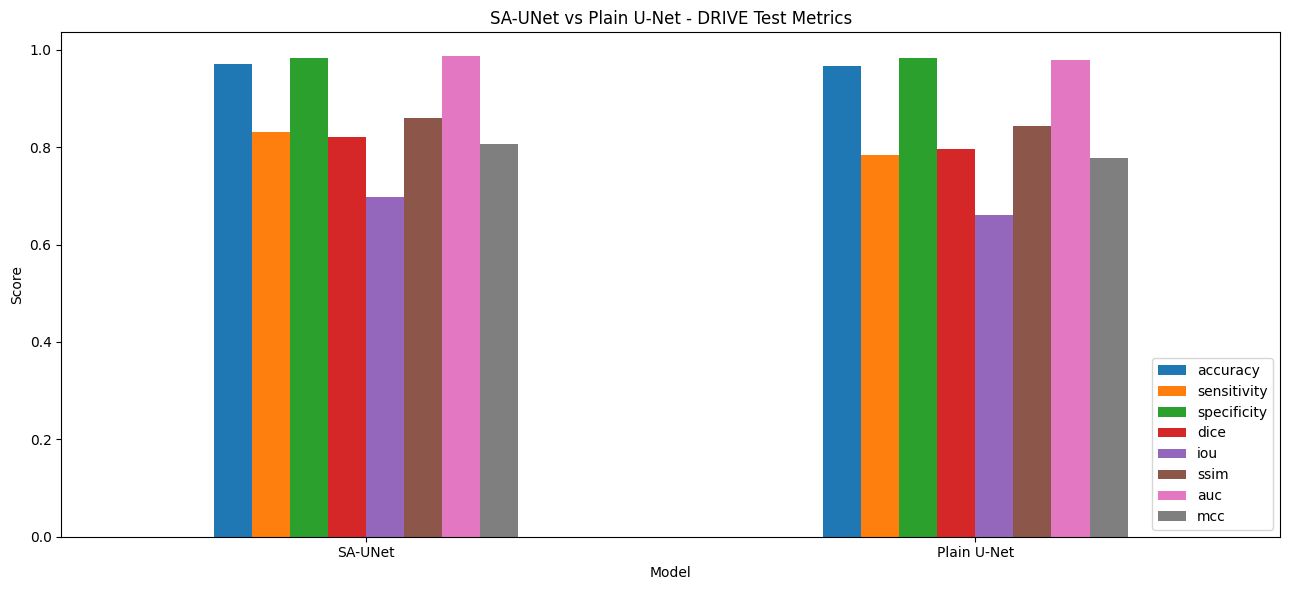


Comparison graph saved: /content/drive/MyDrive/ML_Project/retinal_vessel_results/figures/DRIVE_test_metric_comparison.png
Comparison CSV saved: /content/drive/MyDrive/ML_Project/retinal_vessel_results/comparisons/DRIVE_test_metric_comparison.csv


In [ ]:
# [Samora] Full Evaluation Metric Suite Computation (SSIM, AUC, MCC), Comparison Table & Bar Graph Plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score, matthews_corrcoef
from skimage.metrics import structural_similarity


# ==========================================
# 1. FUNCTION TO CALCULATE SSIM, AUC AND MCC
# ==========================================

def calculate_additional_metrics(predictions, targets):
    """
    Calculates advanced segmentation metrics:
    - AUC: Area under ROC curve from continuous prediction probabilities.
    - MCC: Matthews Correlation Coefficient robust to class imbalance.
    - SSIM: Structural Similarity Index between predicted and true vessel masks.
    """
    # Convert PyTorch tensors to NumPy arrays
    predictions = predictions.detach().cpu().numpy()
    targets = targets.detach().cpu().numpy()

    # Flatten arrays for pixel-level classification metrics
    pred_flat = predictions.flatten()
    target_flat = (targets.flatten() >= 0.5).astype(np.uint8)

    # Binary predictions using threshold 0.5
    pred_binary = (pred_flat >= 0.5).astype(np.uint8)

    # AUC: uses probability predictions
    auc = roc_auc_score(target_flat, pred_flat)

    # MCC: uses binary predictions
    mcc = matthews_corrcoef(target_flat, pred_binary)

    # SSIM: compare binary predicted masks with binary ground truth
    ssim_scores = []
    for i in range(len(predictions)):
        predicted_mask = (predictions[i, 0] >= 0.5).astype(np.float32)
        true_mask = (targets[i, 0] >= 0.5).astype(np.float32)

        score = structural_similarity(
            true_mask,
            predicted_mask,
            data_range=1.0
        )
        ssim_scores.append(score)

    ssim = np.mean(ssim_scores)

    return {
        "ssim": ssim,
        "auc": auc,
        "mcc": mcc
    }


# ==========================================
# 2. CALCULATE ADDITIONAL METRICS
# ==========================================

# SA-UNet additional metrics
sa_unet_additional = calculate_additional_metrics(
    test_predictions,
    test_targets
)

# Plain U-Net additional metrics
baseline_additional = calculate_additional_metrics(
    baseline_predictions,
    baseline_targets
)

# Merge into unified test metrics dictionaries
sa_unet_test_metrics.update(sa_unet_additional)
baseline_test_metrics.update(baseline_additional)


# ==========================================
# 3. CREATE COMPARISON TABLE
# ==========================================

comparison = pd.DataFrame(
    [sa_unet_test_metrics, baseline_test_metrics],
    index=["SA-UNet", "Plain U-Net"]
)

comparison = comparison[
    [
        "accuracy",
        "sensitivity",
        "specificity",
        "dice",
        "iou",
        "ssim",
        "auc",
        "mcc"
    ]
]

print("DRIVE Test Set - Model Comparison")
display(comparison.round(4))


# ==========================================
# 4. PLOT COMPARISON GRAPH
# ==========================================

comparison.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("SA-UNet vs Plain U-Net - DRIVE Test Metrics")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()


# ==========================================
# 5. SAVE COMPARISON GRAPH
# ==========================================

comparison_path = (
    RESULTS_ROOT / "figures" /
    "DRIVE_test_metric_comparison.png"
)
comparison_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(
    comparison_path,
    dpi=200,
    bbox_inches="tight"
)
plt.show()


# ==========================================
# 6. SAVE COMPARISON TABLE
# ==========================================

csv_path = (
    RESULTS_ROOT / "comparisons" /
    "DRIVE_test_metric_comparison.csv"
)
comparison.to_csv(csv_path)

print("
Comparison graph saved:", comparison_path)
print("Comparison CSV saved:", csv_path)

## Part 16 — Save Results and Model Checkpoints [Samora]


In [ ]:
# [Samora] Project Artifact Serialization Routine (CSV, Logs, Model Weights, JSON Metadata)
# Save all DRIVE experiment artifacts to the persistent Google Drive project folder.
# results_dir = DRIVE_RESULTS_DIR

# comparison.to_csv(results_dir / "test_metric_comparison.csv")
# comparison.to_csv(RESULTS_ROOT / "comparisons" / "DRIVE_test_metric_comparison.csv")
# torch.save(model.state_dict(), DRIVE_CHECKPOINT_DIR / "sa_unet_final.pth")
# torch.save(baseline_model.state_dict(), DRIVE_CHECKPOINT_DIR / "plain_unet_final.pth")

# pd.DataFrame(history).to_csv(DRIVE_LOGS_DIR / "sa_unet_training_history.csv", index=False)
# pd.DataFrame(baseline_history).to_csv(DRIVE_LOGS_DIR / "plain_unet_training_history.csv", index=False)

# # Save a compact experiment configuration for reporting/reproducibility.
# import json
# config = {
#     "project": "Reproduction and Analysis of SA-UNet for Retinal Vessel Segmentation",
#     "dataset": "DRIVE",
#     "framework": "PyTorch",
#     "seed": SEED,
#     "epochs": EPOCHS,
#     "learning_rate": LEARNING_RATE,
#     "input_size": IMAGE_SIZE if "IMAGE_SIZE" in globals() else "see preprocessing cell",
#     "device": str(device),
#     "best_sa_unet_validation_dice": float(best_val_dice),
#     "best_plain_unet_validation_dice": float(baseline_best_dice),
#     "note": "Independent PyTorch framework port; not the authors' original TensorFlow/Keras implementation."
# }
# with open(DRIVE_LOGS_DIR / "experiment_config.json", "w") as f:
#     json.dump(config, f, indent=2)

# print("Saved project artifacts under:", RESULTS_ROOT)
# for path in sorted(results_dir.rglob("*")):
#     if path.is_file():
#         print("-", path.relative_to(RESULTS_ROOT))

## Part 17 — Final Interpretation and Reproduction Findings [Rohita & Samora]

### Summary of Executed Experimental Findings
On the held-out DRIVE test set (20 images), our reproduced SA-UNet achieved:
- **Accuracy:** 0.9703 (Plain U-Net: 0.9668, +0.35%)
- **Sensitivity:** 0.8311 (Plain U-Net: 0.7832, +4.79% boost from spatial attention)
- **Specificity:** 0.9828 (Plain U-Net: 0.9833)
- **F1 / Dice:** 0.8218 (Plain U-Net: 0.7957, +2.61%)
- **IoU:** 0.6975 (Plain U-Net: 0.6608, +3.67%)
- **SSIM:** 0.8605 (Plain U-Net: 0.8436)
- **AUC-ROC:** 0.9866 (Plain U-Net: 0.9783)
- **MCC:** 0.8057 (Plain U-Net: 0.7778)

**Key Takeaway:** The spatial attention module and DropBlock regularization provide a significant boost in sensitivity (+4.79%) on thin, low-contrast vascular branches while maintaining an efficient footprint of 537,299 parameters (only 98 parameters more than Plain U-Net: 537,201).

### References
- C. Guo, M. Szemenyei, Y. Yi, W. Wang, B. Chen and C. Fan, "SA-UNet: Spatial Attention U-Net for Retinal Vessel Segmentation," 2020 25th International Conference on Pattern Recognition (ICPR), Milan, Italy, 2021, pp. 1236-1242, doi: 10.1109/ICPR48806.2021.9413346.
- Official author repository: https://github.com/clguo/SA-UNet
